In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

pd.set_option("display.max_columns", None)


In [2]:
# The original UCI data file is whitespace-separated and has no header row.
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"

columns = [
    "mpg", "cylinders", "displacement", "horsepower",
    "weight", "acceleration", "model_year", "origin", "car_name"
]

df = pd.read_csv(
    url,
    sep=r"\s+",
    names=columns,
    na_values="?",
    comment="\t",
    skipinitialspace=True
)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


## 3. Explore and clean the data

In [3]:
print("Dataset information:")
df.info()

print("\nMissing values before cleaning:")
display(df.isnull().sum())

# Horsepower contains '?' values in the original file; these are read as NaN.
df = df.dropna().copy()

# car_name is an identifier/text field, not used as a numeric predictor.
print("\nDataset shape after removing missing rows:", df.shape)
display(df.describe())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car_name      398 non-null    object 
dtypes: float64(5), int64(3), object(1)
memory usage: 28.1+ KB

Missing values before cleaning:


,0
mpg,0
cylinders,0
displacement,0
horsepower,6
weight,0
acceleration,0
model_year,0
origin,0
car_name,0



Dataset shape after removing missing rows: (392, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
count,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000
mean,23.445918,5.471939,194.411990,104.469388,2977.584184,15.541327,75.979592,1.576531
std,7.805007,1.705783,104.644004,38.491160,849.402560,2.758864,3.683737,0.805518
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.000000,4.000000,105.000000,75.000000,2225.250000,13.775000,73.000000,1.000000
50%,22.750000,4.000000,151.000000,93.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,275.750000,126.000000,3614.750000,17.025000,79.000000,2.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000,3.000000


## 4. Select input features and target

In [4]:
# Target: fuel efficiency in miles per gallon
target = "mpg"

# Multiple input features
features = [
    "cylinders", "displacement", "horsepower",
    "weight", "acceleration", "model_year", "origin"
]

X = df[features].copy()
y = df[target].copy()

print("Input features:", features)
print("Target:", target)


Input features: ['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin']
Target: mpg


## 5. Exploratory data analysis

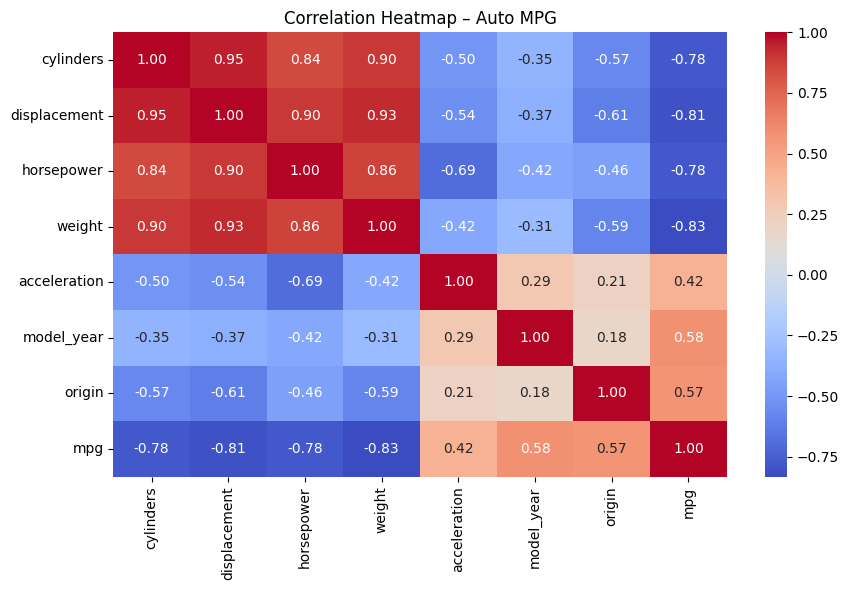

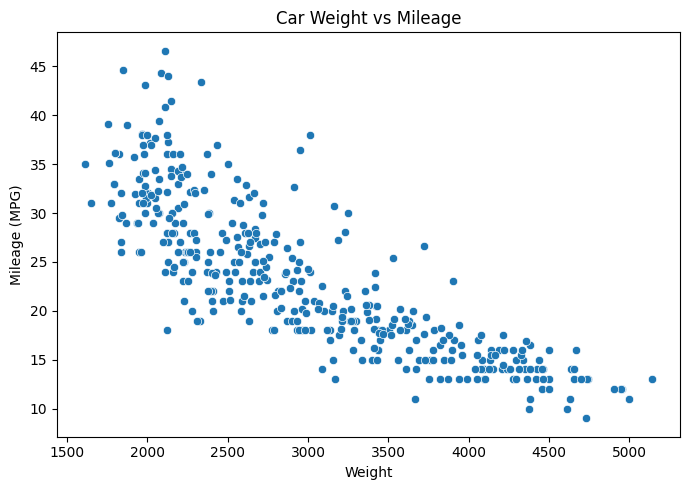

In [5]:
plt.figure(figsize=(9, 6))
sns.heatmap(df[features + [target]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap – Auto MPG")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="weight", y="mpg")
plt.title("Car Weight vs Mileage")
plt.xlabel("Weight")
plt.ylabel("Mileage (MPG)")
plt.tight_layout()
plt.show()


## 6. Split data into training and testing sets

In [6]:
# Use the same split for both models to make the comparison fair.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 313
Testing rows: 79


## 7. Train Single Linear Regression (baseline)

In [7]:
# Baseline model uses only one feature: weight.
single_feature = ["weight"]

single_model = LinearRegression()
single_model.fit(X_train[single_feature], y_train)

single_predictions = single_model.predict(X_test[single_feature])

print("Single Linear Regression coefficient:", single_model.coef_[0])
print("Single Linear Regression intercept:", single_model.intercept_)


Single Linear Regression coefficient: -0.007903610385225605
Single Linear Regression intercept: 47.200526427552106


## 8. Train Multiple Linear Regression

In [8]:
multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)

multiple_predictions = multiple_model.predict(X_test)

coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": multiple_model.coef_
})
display(coefficients)

print("Intercept:", multiple_model.intercept_)


,Feature,Coefficient
0,cylinders,-0.345789
1,displacement,0.015109
2,horsepower,-0.021302
3,weight,-0.006142
4,acceleration,0.037950
5,model_year,0.767743
6,origin,1.613457


Intercept: -18.499361128724768


## 9. Evaluate and compare both models

In [9]:
def regression_metrics(y_true, y_pred, number_of_features):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    n = len(y_true)
    p = number_of_features

    # Adjusted R-squared; defined when n > p + 1.
    adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

    return {
        "R-squared": r2,
        "Adjusted R-squared": adjusted_r2,
        "RMSE": rmse
    }

results = pd.DataFrame([
    {
        "Model": "Single Linear Regression (weight only)",
        **regression_metrics(y_test, single_predictions, 1)
    },
    {
        "Model": "Multiple Linear Regression (7 features)",
        **regression_metrics(y_test, multiple_predictions, len(features))
    }
])

display(results.round(4))

best_model_name = results.loc[results["RMSE"].idxmin(), "Model"]
print("Model with lower test RMSE:", best_model_name)


,Model,R-squared,Adjusted R-squared,RMSE
0,Single Linear Regression (weight only),0.6533,0.6488,4.2064
1,Multiple Linear Regression (7 features),0.7902,0.7695,3.2727


Model with lower test RMSE: Multiple Linear Regression (7 features)


## 10. Actual vs predicted values

,Actual MPG,Predicted MPG
0,26.0,25.841562
1,21.6,26.036745
2,36.1,34.506018
3,26.0,24.895532
4,27.0,28.425987
5,28.0,30.561382
6,13.0,8.586943
7,26.0,30.721856
8,19.0,20.556786
9,29.0,28.646823


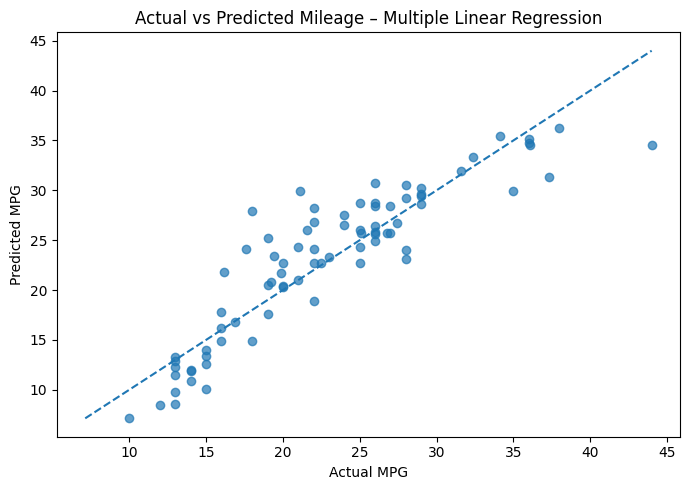

In [10]:
comparison = pd.DataFrame({
    "Actual MPG": y_test.values,
    "Predicted MPG": multiple_predictions
})
display(comparison.head(10))

plt.figure(figsize=(7, 5))
plt.scatter(y_test, multiple_predictions, alpha=0.7)
low = min(y_test.min(), multiple_predictions.min())
high = max(y_test.max(), multiple_predictions.max())
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title("Actual vs Predicted Mileage – Multiple Linear Regression")
plt.tight_layout()
plt.show()


## 11. Predict mileage for a new car

Enter example vehicle details below. These are illustrative inputs; change them to test other cars.

In [11]:
new_car = pd.DataFrame([{
    "cylinders": 4,
    "displacement": 140,
    "horsepower": 90,
    "weight": 2500,
    "acceleration": 15.5,
    "model_year": 82,
    "origin": 1
}])

predicted_mpg = multiple_model.predict(new_car[features])[0]
print(f"Predicted mileage: {predicted_mpg:.2f} MPG")


Predicted mileage: 30.12 MPG
